In [4]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))

from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from cnct_search import cnct_search

import DAS_processing as DASproc
import DAS_model_inversion as DASmi
import DAS_plots as DASplt
from cnct_search import cnct_search, cnct_search_scat, submit_detached

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import pickle

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob

import scipy
import scipy.signal as scisig
from scipy.integrate import cumulative_trapezoid
from scipy.fft import fft, ifft, fftfreq
from scipy.signal import butter, filtfilt

%matplotlib inline
import copy

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# medium parameters
vp=4291.584
vs=2407.92
rho=2600
wave='SS'


#source location
xs=82.0
ys=3700.25882
ts=1.9096

#fiber gauge length
gl=5

#estimate the critican angle
theta_c = np.rad2deg(np.arcsin(vs/vp))

In [6]:
#import scattering data
with open("./data/scattering_data.pkl", "rb") as f:
    scat_data = pickle.load(f)

scat_data= DASmi.fft_traces_scat(scat_data)

#Geometric factor for displacement to strain_rate conversion along the fiber
alpha=0.5
gfactor=DASmi.geometric_factor(scat_data, gl, vs, alpha=alpha)

#update dictionary with geometric factor
scat_data.update({
    "Gr": gfactor['Gr'],
    "Gt": gfactor['Gt'],
    "omega": gfactor['omega'],

})
DASmi.add_noise_weights_scat(scat_data)
    # adds snr_noise_ref, w_noise_ref, snr_noise_tr, w_noise_tr

#copying the data to scat_original and applying a lowpass filter to the transmitted traces

scat_orig = copy.deepcopy(scat_data)#keep a copy of the original data before filtering
DASproc.lowpass_tukey_zerophase_scat(scat_data, 'transmitted_traces', f_end=320, alpha=0.6);



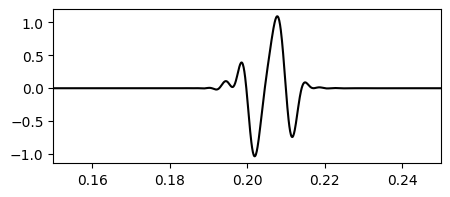

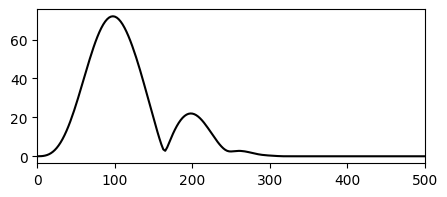

In [4]:
#Testing the forward modeling function RfromT (from transmitted traces)
ct=1e-11
cn=ct
eps=0.06
idx=20
out = DASmi.RfromT(scat_data, idx, vp, vs, rho, cn, ct, eps, wave='SS')

time=out['time']
N=len(time)
freqs=out['freqs']
spectra=np.abs(out['Er_omega'])

plt.close('all')
plt.figure(figsize=(5,2))
plt.plot(time, out['Er_time'], color='k')
plt.xlim([0.15, 0.25])
plt.show()


plt.figure(figsize=(5,2))
plt.plot(freqs[:N//2], spectra[:N//2], color='k')
plt.xlim([0, 500])

plt.show()


In [7]:
#general parameters
path='./inv_results/RfromT'

# medium parameters
medium=(vp,vs,rho,wave)
snr_min=7
search_mode='full'

eps=0.06
search_space=((0.01,3.5), (1e-14, 1e-8))
nsearch=(50, 100)
cc='signed'
max_lag=35

n_pair=len(scat_data['theta_r_deg']  )
idx_range=np.arange(n_pair)

In [ ]:
file1='weighted_ratio_cn'

trace_opts = {"weight": "noise_cap",       # "noise" or "noise_cap"
              "select": ("snr", 7.0)}
grid_cn='ratio_cn'
search_param_weighted=(search_mode, 
                   grid_cn, 
                   eps, 
                   search_space,
                   nsearch, 
                   cc,
                   None,#constraint,
                   trace_opts,
                   max_lag)

#sending job to a node for processing
job1 = submit_detached(cnct_search_scat, scat_data, idx_range, medium, search_param_weighted,
                      file1, out_root=path)

submitted weighted_ratio_cn (pid 572548); log: inv_results/RfromT/weighted_ratio_cn/weighted_ratio_cn.log


In [8]:
file2='weighted_ratio_cn_snr10'

trace_opts = {"weight": "noise_cap",       # "noise" or "noise_cap"
              "select": ("snr", 10.0)}
grid_cn='ratio_cn'
search_param_weighted=(search_mode, 
                   grid_cn, 
                   eps, 
                   search_space,
                   nsearch, 
                   cc,
                   None,#constraint,
                   trace_opts,
                   max_lag)


# sending job to a node for processing
job2 = submit_detached(cnct_search_scat, scat_data, idx_range, medium, search_param_weighted,
                      file2, out_root=path)

submitted weighted_ratio_cn_snr10 (pid 3456880); log: inv_results/RfromT/weighted_ratio_cn_snr10/weighted_ratio_cn_snr10.log


In [ ]:
#grouping results
run=file2
dir=path+'/'+run
group2 = DASmi.optimal_angle_groups(dir, scat_data)

#picking the grouping
k=4
g2=group2['K'][k]['groups']

#extracting search results for the optimal groups
p2  = DASmi.extracting_search(dir , g2, scat_data)

# quantifying waveform match
wave_fit = DASmi.waveform_fitness(dir, scat_data, g2) 


K=1: total cost_norm 0.552
   angle 45.1-35.1 deg  pairs 0-31 (n=32)  best cn 2.31e-10 (10%: 1.52e-10-2.66e-10)  ct 6.60e-11  cn/ct 3.50  cost_norm 0.55
K=2: total cost_norm 0.488, gain vs K=1: 11.6%   <- recommended
   angle 45.1-40.9 deg  pairs 0-12 (n=13)  best cn 1.52e-10 (10%: 1.15e-10-1.75e-10)  ct 4.34e-11  cn/ct 3.50  cost_norm 0.46
   angle 40.6-35.1 deg  pairs 13-31 (n=19)  best cn 3.51e-10 (10%: 2.31e-10-4.64e-10)  ct 3.51e-08  cn/ct 0.01  cost_norm 0.50
K=3: total cost_norm 0.478, gain vs K=2: 1.9%
   angle 45.1-40.9 deg  pairs 0-12 (n=13)  best cn 1.52e-10 (10%: 1.15e-10-1.75e-10)  ct 4.34e-11  cn/ct 3.50  cost_norm 0.46
   angle 40.6-36.3 deg  pairs 13-27 (n=15)  best cn 3.51e-10 (10%: 2.31e-10-4.04e-10)  ct 3.51e-08  cn/ct 0.01  cost_norm 0.46
   angle 36.0-35.1 deg  pairs 28-31 (n=4)  best cn 4.64e-10 (10%: 2.31e-10-5.34e-10)  ct 4.64e-08  cn/ct 0.01  cost_norm 0.56
K=4: total cost_norm 0.474, gain vs K=3: 1.0%
   angle 45.1-43.3 deg  pairs 0-5 (n=6)  best cn 1.32e-10 (

In [11]:
# Purpose: table of the waveform fitness of each group's best fit (K groups of g2)
# Input  : wave_fit = DASmi.waveform_fitness(dir, scat_data, g2)
# Output : fit_table (pandas DataFrame, one row per group)
fit_table = pd.DataFrame([{
    "Group": k,                                                    # group number within K
    "No. pairs": r["pairs"].size,
    "Angles (deg)": f"{r['angle'][1]:.1f}-{r['angle'][0]:.1f}",    # largest-smallest angle
    "cost_norm": r["cost_norm"],                                   # L2 cost at the group best node
    "S_mean": r["S_mean"],                                         # mean similarity (shape + amplitude)
    "rho_mean": r["rho_mean"],                                     # mean shape match
    "amp_mean": r["amp_mean"],                                     # mean model/data amplitude
} for k, r in enumerate(wave_fit["groups"])]).set_index("Group")

fit_table.round(2)



,No. pairs,Angles (deg),cost_norm,S_mean,rho_mean,amp_mean
Group,,,,,,
0,6,45.1-43.3,0.33,0.81,0.82,0.87
1,7,43.0-40.9,0.50,0.67,0.70,0.74
2,15,40.6-36.3,0.46,0.64,0.70,0.68
3,4,36.0-35.1,0.56,0.57,0.66,0.57


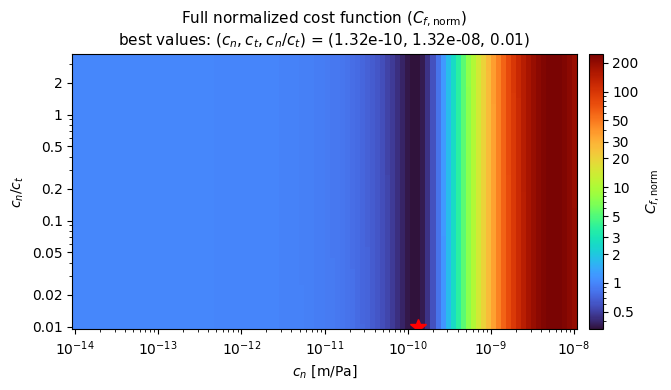

saved inv_results/RfromT/weighted_ratio_cn_snr10/other_plots/group0_full_cost_norm.png


(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Group 0: Full normalized cost function ($C_{f,\\mathrm{norm}}$)\nbest values: $(c_n, c_t, c_n/c_t)$ = (1.32e-10, 1.32e-08, 0.01)'}, xlabel='$c_n$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [13]:
import importlib
importlib.reload(DASplt)

#plotting group results
group=0

plot_file=dir+'/group'+str(group)+'_'+run+'.pkl'
#options
which="full" # "full" or "constraint"
output="cost" # "cost" or "s_hat

plt.close('all')

DASplt.plot_cnct_search(plot_file, which="full", output="cost_norm", group=group)

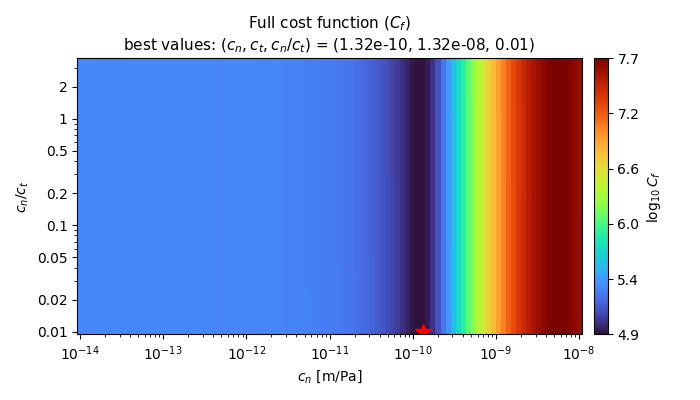

Button(description='Save figure', icon='save', style=ButtonStyle(), tooltip='save to inv_results/RfromT/weight…

In [14]:
%matplotlib widget
fig, ax, picks = DASplt.pick_ratiosearch(plot_file, which="full", output="cost", load_existing=False, group=group)

In [16]:
#plot waveforms for the picked pairs
DASplt.plot_waveform_picks_scat(dir, scat_data, group=group)        # dir = the run folder, e.g. './inv_results/RfromT/weighted_ratio_cn'


1

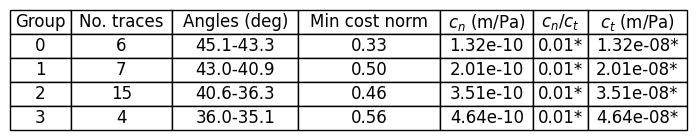

In [8]:
fig, ax, rows = DASplt.inversion_table('./inv_results/RfromT/weighted_ratio_cn_snr10', scat_data, save_dir='./plots/DASplots', fname=None, font_size=12, dpi=400)
